# ENGR 1451/2451 — Weekly Assignment 6
**10 points**

Practice fitting and interpreting a simple linear regression, making predictions, examining residuals and diagnostic plots, and writing a reusable function to compare model fits.

**Due:** See Canvas.

Complete the work directly in this notebook. Show your Python code and give brief written explanations where requested.

## What to hand in

Work this assignment with the **course tutor** in the class project. Use the course tutor as your AI help for this assignment; it keeps the record for you, so you do not need to write a separate log.

At the end of each working session, type **"make my record"** in the chat. Copy the block it produces and paste it into the **Session records** cell near the bottom of this notebook.

You do not have to finish in one sitting. To continue later, start a new chat in the same project, state which assignment you are working on and where you stopped, and continue from there. Paste the new session record below the previous one.

Session records are not graded for correctness or for how much help you needed. The code and written answers must still be your own.

## Setup

All data are embedded below; no CSV file is needed.

Select observations by conditions, not row positions. Calculate counts, ranges, and cutoffs from the data. Label axes with units. Keep full precision in calculations and round only displayed results. Keep written comments brief and tied to your results.

Fit every regression with an **intercept**. All fit measures in this assignment describe the same observations used to fit the model. The imports below match the packages used in week 6.

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf
from IPython.display import display

pd.set_option("display.precision", 6)

## LE6-1. Fit and use a regression line (3 pts)

Each row describes one laptop. `battery_Wh` is battery capacity in watt-hours and `runtime_h` is battery runtime in hours. These are synthetic observational records.

### A. Prepare the data and fit the line (1 pt)

Create `complete` by keeping the ID and both regression variables and dropping rows missing either variable. Report the retained and excluded counts.

Fit runtime from capacity with **`np.polyfit(..., deg=1)`**. Store `slope` and `intercept` and display them. Plot the observations and fitted line across the observed capacity range, with labeled axes and a legend.

Write the fitted equation and interpret the slope, including units and appropriate association wording.

**Answer:** The fitted equation is approximately 0.1x + 1.53. The slope of this fitted line is approximately the estimated usable battery runtime in hours that is gained per watt hour of battery capacity to the cell itself.

0.09989465115165447X + 1.5354115787961526


Text(0, 0.5, 'Battery runtime (h)')

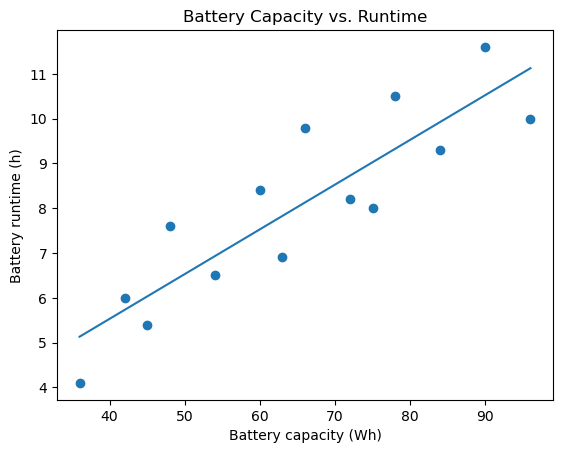

In [60]:
battery_Wh = [36, 42, 45, 48, 54, 60, 63, 66,
              72, 75, 78, 84, 90, 96, np.nan, 80]
laptops = pd.DataFrame({
    "laptop_id": [f"L{number:02d}" for number in range(1, len(battery_Wh) + 1)],
    "battery_Wh": battery_Wh,
    "runtime_h": [4.1, 6.0, 5.4, 7.6, 6.5, 8.4, 6.9, 9.8,
                  8.2, 8.0, 10.5, 9.3, 11.6, 10.0, 8.5, np.nan],
})
xcol = "battery_Wh"
ycol = "runtime_h"
laptop_labels = {
    "battery_Wh": "Battery capacity (Wh)",
    "runtime_h": "Battery runtime (h)",
}

# Your complete-case selection and retained/excluded counts here.
complete = laptops.dropna()
retained = len(complete["runtime_h"])
excluded = len(laptops["runtime_h"]) - retained

# Fit with np.polyfit(), storing slope and intercept.
slope, intercept = np.polyfit(complete[xcol],complete[ycol], deg=1)

print(f"{slope}X + {intercept}")

# Plot the observations and fitted line over the observed x range.
fig, ax = plt.subplots()
x_vals = np.linspace(complete[xcol].min(),complete[xcol].max(), 100)

ax.scatter(complete[xcol], complete[ycol])
ax.plot(x_vals, intercept + slope * x_vals)
ax.set_title("Battery Capacity vs. Runtime")
ax.set_xlabel(laptop_labels[xcol])
ax.set_ylabel(laptop_labels[ycol])

### B. Predict and check the range (1 pt)

Add `predicted_runtime_h` and `inside_observed_range` to `prediction_data`. Use the unrounded coefficients and the observed minimum and maximum capacity; include both endpoints. Display the table.

Identify interpolation and extrapolation. Explain briefly why the intercept has limited practical meaning here and why the association does not establish the effect of replacing a laptop's battery.

**Answer:** The first battery value of 72Wh is interpolation as it falls within the tested range and it can safely be said that it will likely perform around the mark estimated. The 120Wh battery is extrapolated as we have no general idea of how batteries outside the tested range will perform. The intercept value of roughly 1.53 has no practical meaning here as it is essentially saying a 0Wh battery will have a 1.53 hour runtime, which is simply false. The association is not the same as replacing the battery because real world battery usability has many additional confounding factors, not simply battery capacity.

In [61]:
prediction_data = pd.DataFrame({"battery_Wh": [72.0, 120.0]})

# Your predicted_runtime_h and inside_observed_range columns here.
prediction_data["predicted_runtime_h"] = prediction_data["battery_Wh"]*slope + intercept
prediction_data["inside_observed_range"] = (prediction_data["battery_Wh"] >= complete["battery_Wh"].min()) & (prediction_data["battery_Wh"] <= complete["battery_Wh"].max())
# Display the prediction table.
prediction_data.head()

,battery_Wh,predicted_runtime_h,inside_observed_range
0,72.0,8.727826,True
1,120.0,13.522770,False


### C. Fit with statsmodels (1 pt)

Fit **`smf.ols("runtime_h ~ battery_Wh", data=complete).fit()`** and name the model `laptop_fit`. The formula is `response ~ predictor` and includes an intercept.

Display a coefficient table comparing the NumPy values with `laptop_fit.params["Intercept"]` and `laptop_fit.params["battery_Wh"]`. Do the methods agree to the displayed precision?

**Answer:** The methods do agree to the displayed precision.

In [62]:
# Fit laptop_fit with statsmodels.
laptop_fit = smf.ols("runtime_h ~ battery_Wh", data=complete).fit()
print(laptop_fit.params)

# Compare the NumPy and statsmodels coefficients in one labeled table.
summary_fits = pd.DataFrame( { 
    "Model": ["smf", "numpy"],
    "Slope": [laptop_fit.params[xcol], slope],
    "Intercept": [laptop_fit.params["Intercept"], intercept]
})

summary_fits.head()

Intercept     1.535412
battery_Wh    0.099895
dtype: float64


,Model,Slope,Intercept
0,smf,0.099895,1.535412
1,numpy,0.099895,1.535412


## LE6-2. Residuals and fit quality (3 pts)

Use the same `complete` observations throughout this exercise.

### A. Find the largest miss (1 pt)

Create `laptop_results` by adding `fitted` and `residual` columns to a copy of `complete`, using `laptop_fit.fittedvalues` and `laptop_fit.resid`. Display the table.

Select `largest_residual_rows` using `.loc[]` and a condition on the maximum **absolute residual**. Calculate the maximum from the data and keep all ties.

Report the selected ID, observed and fitted runtimes, and signed residual. Use $e_i=y_i-\widehat y_i$ to explain whether the model overpredicts or underpredicts, with units.

**Answer:** The selected laptop ID is 7, the model generally underpredicts slightly more often than it overpredicts. The magnitudes of the underpredictions tend to be more off than the overpredictions, so the model generally slightly underpredicts.

In [63]:
# Create and display laptop_results.
laptop_results = pd.DataFrame({
    "fitted": laptop_fit.fittedvalues,
    "residual": laptop_fit.resid
})

# Select and display largest_residual_rows using a Boolean condition.
laptop_results.head()

isMax = np.abs(laptop_results["residual"]) == np.abs(laptop_results["residual"]).max()
largest_residual_rows = complete.loc[isMax]

max_resid_id = largest_residual_rows["laptop_id"]

residuals_calculated = complete["runtime_h"] - laptop_results["fitted"]

print(f"Maximum residual ID: {max_resid_id}")
print(f"e = y - yfitted: {residuals_calculated}")

Maximum residual ID: 7    L08
Name: laptop_id, dtype: object
e = y - yfitted: 0    -1.031619
1     0.269013
2    -0.630671
3     1.269645
4    -0.429723
5     0.870909
6    -0.928775
7     1.671541
8    -0.527826
9    -1.027510
10    1.172806
11   -0.626562
12    1.074070
13   -1.125298
dtype: float64


### B. Calculate the residual size (1 pt)

Using the actual row count $n$, calculate

$$
\mathrm{SSE}=\sum_i e_i^2,\qquad
\mathrm{MSE}=\frac{\mathrm{SSE}}{n},\qquad
\mathrm{RMSE}=\sqrt{\mathrm{MSE}}.
$$

Display MSE in h$^2$ and RMSE in h, and interpret RMSE in one sentence. Keep `n`, `sse`, and `rmse` for part C.

**Use denominator $n$.** `laptop_fit.mse_resid` uses $n-2$; its square root is the residual standard error, a different quantity.

**Answer:** The root mean square error is roughly 1hour, which is the average error that the model under or overpredicts.

In [64]:
# Calculate n, sse, mse, and rmse from laptop_results.
n = len(laptop_results["fitted"])
sse = (laptop_results["residual"]**2).sum()
mse = sse/n
rmse = np.sqrt(mse)

# Display MSE and RMSE with units.
print(f"MSE: {mse:.4f}h^2")
print(f"RMSE: {rmse:.4f}h")

MSE: 0.9478h^2
RMSE: 0.9735h


### C. Compare the line with the mean-only baseline (1 pt)

Calculate

$$
\mathrm{SST}=\sum_i(y_i-\bar y)^2,\qquad
\mathrm{RMSE}_{\text{mean-only}}=\sqrt{\frac{\mathrm{SST}}{n}},\qquad
R^2=1-\frac{\mathrm{SSE}}{\mathrm{SST}}.
$$

Calculate Pearson's $r$ for the same pairs. Display the two RMSE values, your $R^2$, `laptop_fit.rsquared`, and $r^2$ together.

Interpret $R^2$ and the improvement over predicting the same mean runtime for every laptop. These measures describe the fitting data; do they establish performance on new laptops?

**Answer:** The R^2 values are all congruent, it is ~.77, it shows a relatively strong correlation between the fitted model and the original values. The model does not describe performance on new laptops, as the correlation is not nearly perfect and there are other confounding factors that can determine battery performance. 

In [65]:
# Calculate sst, mean-only RMSE, R-squared, and Pearson r.
sst = ((complete["runtime_h"] - complete["runtime_h"].mean())**2).sum()
rmse_mean_only = np.sqrt(sst/n)
r_squared_eqn = 1 - (sse/sst)
r_squared_fit = laptop_fit.rsquared
pearson_r = complete["runtime_h"].corr(laptop_results["fitted"])
r_squared_pearson = pearson_r**2

# Display the two RMSE values and compare the three R-squared values.
print(f"RMSE Mean Only: {rmse_mean_only:.4f}h, RMSE: {rmse:.4f}h")
print(f"R^2 (equation): {r_squared_eqn:.7f}, R^2 (function): {r_squared_fit:.7f}, R^2 (pearson): {r_squared_pearson:.7f}")

RMSE Mean Only: 2.0341h, RMSE: 0.9735h
R^2 (equation): 0.7709305, R^2 (function): 0.7709305, R^2 (pearson): 0.7709305


## LE6-3. Check the center, spread, and shape (2 pts)

**Run the plotting helper unchanged.** It displays the fitted line, residuals versus the predictor, a residual histogram, and a normal probability (Q-Q) plot. Approximate alignment with the Q-Q reference line is a rough check of Gaussian shape.

Gaussian shape concerns the model errors; the raw predictor and response need not be normally distributed, and normality is not required to calculate a least-squares line.

In [66]:
# Provided plotting code: run this cell unchanged.
def plot_regression_diagnostics(data, fit, xcol, ycol, xlabel, ylabel,
                                residual_label, title):
    """Display four diagnostics for the same observations used to fit the model."""
    x_grid = np.linspace(data[xcol].min(), data[xcol].max(), 100)
    new_data = pd.DataFrame({xcol: x_grid})
    residuals = fit.resid
    fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)

    ax = axes[0, 0]
    ax.scatter(data[xcol], data[ycol], alpha=0.75)
    ax.plot(x_grid, fit.predict(new_data), color="darkorange",
            linewidth=2, label="Least-squares line")
    ax.set(xlabel=xlabel, ylabel=ylabel, title="Observations and fitted line")
    ax.legend()

    ax = axes[0, 1]
    ax.scatter(data[xcol], residuals, alpha=0.75)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel=xlabel, ylabel=residual_label, title="Residuals versus predictor")

    ax = axes[1, 0]
    ax.hist(residuals, bins="auto", edgecolor="black")
    ax.set(xlabel=residual_label, ylabel="Count", title="Residual histogram")

    (theoretical, ordered), (qq_slope, qq_intercept, _) = stats.probplot(
        residuals, dist="norm", fit=True
    )
    ax = axes[1, 1]
    ax.scatter(theoretical, ordered, alpha=0.75)
    reference_x = np.array([theoretical.min(), theoretical.max()])
    ax.plot(reference_x, qq_intercept + qq_slope * reference_x,
            color="darkorange", linewidth=2)
    ax.set(xlabel="Theoretical normal quantile", ylabel=residual_label,
           title="Normal probability (Q-Q) plot")

    fig.suptitle(title, fontsize=14)
    plt.show()
    return axes

### A. Inspect the laptop model (1 pt)

Call `plot_regression_diagnostics()` for `complete` and `laptop_fit`, using `laptop_labels`, `"Residual (h)"`, and title `"Laptop runtime model"`.

Complete the table with brief observations. Use cautious language for this small dataset: the plots provide evidence but do not prove the assumptions.

| Check | Evidence from the laptop plots |
|---|---|
| Center: clear residual curvature? | No residual curvature, residuals look like they average out to roughly zero |
| Spread: a clear fan or funnel? | Neither a clear nor funnel, looks like an oval cluster |
| Shape: roughly Gaussian residuals? | Residuals are not a normal distribution in this small of a dataset looking at the histogram, NOT roughly Guassian |

**Answer:**

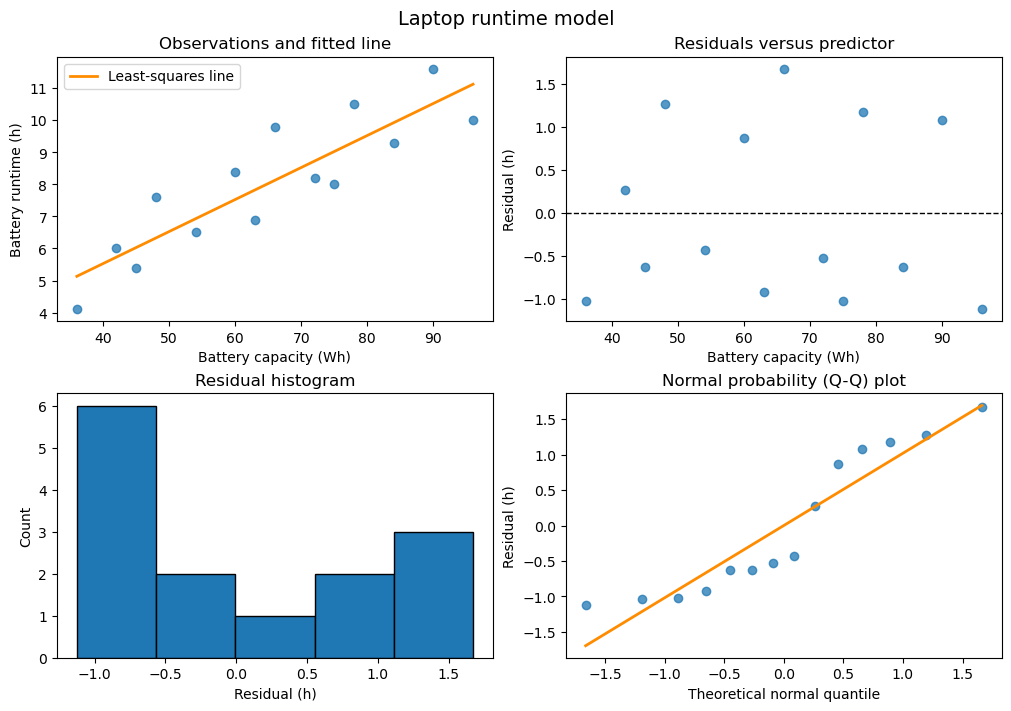

array([[<Axes: title={'center': 'Observations and fitted line'}, xlabel='Battery capacity (Wh)', ylabel='Battery runtime (h)'>,
        <Axes: title={'center': 'Residuals versus predictor'}, xlabel='Battery capacity (Wh)', ylabel='Residual (h)'>],
       [<Axes: title={'center': 'Residual histogram'}, xlabel='Residual (h)', ylabel='Count'>,
        <Axes: title={'center': 'Normal probability (Q-Q) plot'}, xlabel='Theoretical normal quantile', ylabel='Residual (h)'>]],
      dtype=object)

In [67]:
# Your call to plot_regression_diagnostics() for the laptop model here.
plot_regression_diagnostics(complete, laptop_fit, xcol, ycol, laptop_labels[xcol], laptop_labels[ycol], "Residual (h)", "Laptop runtime model")

### B. Compare two diagnostic problems (1 pt)

Run the provided code. `runs` contains synthetic process yield measurements (% of starting material recovered); `sensor` contains simulated signal measurements (mV) at applied loads (N).

The code fits each model and displays its residual plot. Complete the table, distinguishing a problem with the average relationship from a problem with the spread. Why would a residual histogram alone be insufficient to check these features?

| Dataset | Main concern: center or spread? | Plot evidence |
|---|---|---|
| Process yield | center | curved residual plot |
| Sensor calibration | spread | fan shaped residual plot |

**Answer:**

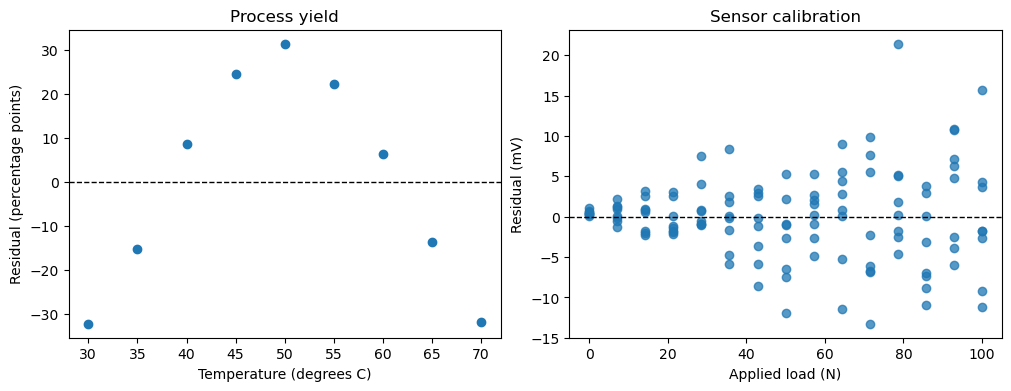

In [68]:
# Provided data, fits, and plots: run this cell unchanged.
runs = pd.DataFrame({
    "temperature_C": [30, 35, 40, 45, 50, 55, 60, 65, 70],
    "yield_pct": [31, 48, 72, 88, 95, 86, 70, 50, 32],
})
rng = np.random.default_rng(1451)
load_N = np.repeat(np.linspace(0, 100, 15), 8)
sensor = pd.DataFrame({
    "load_N": load_N,
    "signal_mV": 10 + 1.2 * load_N
                 + (0.5 + 0.08 * load_N) * rng.normal(size=load_N.size),
})

yield_fit = smf.ols("yield_pct ~ temperature_C", data=runs).fit()
sensor_fit = smf.ols("signal_mV ~ load_N", data=sensor).fit()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].scatter(runs["temperature_C"], yield_fit.resid)
axes[0].set(xlabel="Temperature (degrees C)",
            ylabel="Residual (percentage points)", title="Process yield")
axes[1].scatter(sensor["load_N"], sensor_fit.resid, alpha=0.75)
axes[1].set(xlabel="Applied load (N)", ylabel="Residual (mV)",
            title="Sensor calibration")
for ax in axes:
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
plt.show()

## LE6-4. Write a function and compare sensitivity (2 pts)

Large residuals measure vertical misses; **leverage** concerns how far $x$ is from its center. Compare fits to assess **influence on the slope**.

### A. Write and call your function (1 pt)

Write **`fit_and_summarize(data)`** to fit `runtime_h ~ battery_Wh` with statsmodels and return a `pd.Series` containing `"n"`, `"intercept_h"`, `"slope_h_per_Wh"`, and `"RMSE_h"`. Use denominator $n$ for RMSE.

Use the `data` argument and locally fitted model for every calculation. Return full-precision numbers; do not use `complete`, `laptop_fit`, or earlier coefficients inside the function.

**First call:** Analyze `complete`, store the result as `all_summary`, and display it.

In [69]:
def fit_and_summarize(data):
    """Return n, intercept, slope, and RMSE for the supplied observations."""
    # Write your function body here.
    fit = smf.ols("runtime_h ~ battery_Wh", data=data).fit()
    n = len(data["runtime_h"])
    intercept_h = fit.params["Intercept"]
    slope_h_per_Wh = fit.params["battery_Wh"]
    rmse_h = np.sqrt((fit.resid**2).sum()/n)
    return pd.Series({"n": n, "intercept_h": intercept_h, "slope_h_per_Wh": slope_h_per_Wh , "RMSE_h": rmse_h})


# First call: analyze complete and display all_summary.
all_summary = fit_and_summarize(complete)
all_summary.head()

n                 14.000000
intercept_h        1.535412
slope_h_per_Wh     0.099895
RMSE_h             0.973525
dtype: float64

### B. Compare two omissions (1 pt)

Calculate absolute capacity distances from the mean in `complete`. Select `farthest_capacity_rows` with a condition on the maximum distance, keeping all ties. Display their IDs and capacities.

Create two separate datasets by filtering `complete` on `laptop_id`:

- `without_largest_residual`: exclude IDs in `largest_residual_rows` from LE6-2A.
- `without_farthest_capacity`: exclude IDs in `farthest_capacity_rows`.

**Second and third calls:** Apply your function to the two reduced datasets. Combine their returned Series with `all_summary` into a table with one row per dataset. Add `slope_change` relative to the original slope; display slopes and changes to at least five decimal places. Keep fitting and summary calculations inside the function.

Which omission changes the slope more? Compare this with the largest-residual observation. Explain why an improved fit measure alone would not justify deleting a valid observation.

**Answer:** Farthest capacity omission changes slope much more. It is many times greater than the change omitting the highest residual. This does not justify deleting a valid observation, as to omit observations there needs to be a clear issue with the sampling or n/a data points, simply not fitting the model is not enough to justify deleting an observation.

In [70]:
# Select and display farthest_capacity_rows.
capacity_dist = (complete[xcol] - complete[xcol].mean()).abs()
farthest_capacity_rows = complete.loc[capacity_dist.abs() == capacity_dist.abs().max()]
print("Farthest capacity rows, ID: ", farthest_capacity_rows["laptop_id"], ", capacity: ", farthest_capacity_rows["battery_Wh"])
# Filter complete to create both reduced datasets.
without_largest_residual = complete.loc[~complete["laptop_id"].isin(largest_residual_rows["laptop_id"])]
without_farthest_capacity = complete.loc[~complete["laptop_id"].isin(farthest_capacity_rows["laptop_id"])]

# Call fit_and_summarize() for each reduced dataset.
without_large_resid_summ = fit_and_summarize(without_largest_residual)
without_farthest_cap_summ = fit_and_summarize(without_farthest_capacity)

# Combine the three returned Series and add slope_change.
all_summary["slope_change"] = 0
without_large_resid_summ["slope_change"] = all_summary["slope_h_per_Wh"] - without_large_resid_summ["slope_h_per_Wh"]
without_farthest_cap_summ["slope_change"] = all_summary["slope_h_per_Wh"] - without_farthest_cap_summ["slope_h_per_Wh"]

total_summary = pd.DataFrame({
    "complete": all_summary,
    "without_largest_residual": without_large_resid_summ ,
    "without_farthest_capacity": without_farthest_cap_summ,
})

total_summary.head()

Farthest capacity rows, ID:  13    L14
Name: laptop_id, dtype: object , capacity:  13    96.0
Name: battery_Wh, dtype: float64


,complete,without_largest_residual,without_farthest_capacity
n,14.000000,13.000000,13.000000
intercept_h,1.535412,1.434788,0.936477
slope_h_per_Wh,0.099895,0.099464,0.110856
RMSE_h,0.973525,0.888331,0.940216
slope_change,0.000000,0.000431,-0.010961


## Session records

At the end of each working session, type **"make my record"** in the chat and paste the block it produces into the cell below. If you work across several sessions, paste each new block underneath the previous one.

<!-- Paste your session record blocks in this cell, one after another. -->

*(session records go here)*

{
  "schema_version": "engr-tutor-export-2",
  "assignment": "WA6",
  "export_n": 1,
  "session_date": "2026-10-13",
  "messages": [
    {"i": 1, "who": "student", "text": "how do you plot a line on the same plot as a scatter plot with plt"},
    {"i": 2, "who": "tutor", "text": "Good question to ask before you start building. The plot itself is one of the easier parts once you see the pattern. The key idea is that every drawing call on the same axes object lands on the same plot. You make one set of axes with plt.subplots(), then call ax.scatter for the points and ax.plot for the line on that same ax. [trimmed: toy example on plant height vs days, explanation of plt.subplots, ax.scatter, np.linspace, ax.plot, label= and ax.legend(), axis labels, plt.show(), and a note that matplotlib silently skips points with a missing coordinate] Want me to explain anything else, such as how np.polyfit hands back its coefficients?"},
    {"i": 3, "who": "student", "text": "adding a column to a dataset"},
    {"i": 4, "who": "tutor", "text": "In pandas you add a column by assigning to a new column name in square brackets. If the name doesn't exist yet, pandas creates the column. If it does exist, pandas overwrites it. [trimmed: toy bakery example with calculated, scalar, and Boolean columns; alignment by row label; .copy() versus a second name; SettingWithCopyWarning; .round() returns a new object; displaying the frame] Want to go further into any of this, such as how the index alignment works when the row labels have gaps?"},
    {"i": 5, "who": "student", "text": "how does smf.ols.fit work"},
    {"i": 6, "who": "tutor", "text": "Fitting a regression in statsmodels takes two steps: smf.ols(...) describes the model, and .fit() actually estimates it. [trimmed: toy ice-cream example; formula string, automatic intercept, automatic dropping of rows with missing values, AttributeError without .fit(); table of results attributes; params labels and KeyError; order differs from np.polyfit; row labels of fittedvalues and resid; .predict(); NumPy and statsmodels agreement up to roundoff] Want me to go through what the sections of .summary() report, or how .mse_resid differs from the MSE with denominator n?"},
    {"i": 7, "who": "student", "text": "having trouble finding the absolute max residual for le6-2"},
    {"i": 8, "who": "tutor", "text": "Finding the largest miss is the core step of LE6-2A, so it's worth getting right. Can you paste the cell you have so far, along with its output or the full error message? Then I can see exactly where it's going wrong. While you grab that, here's a question to think about. The selection is a .loc[] whose condition compares every absolute residual with the largest absolute residual. Why does the prompt want absolute values rather than the plain .max() of the residuals, and why a condition rather than something like .idxmax()?"},
    {"i": 9, "who": "student", "text": "i was using laptops not complete so the counts didnt add up for using the mask"},
    {"i": 10, "who": "tutor", "text": "Good catch, and you found it yourself. That mismatch is exactly the kind of bug that's hard to see. [trimmed: why laptop_fit's fitted values and residuals carry complete's row labels; NaN on extra rows, identically-labeled Series error, and counts covering rows outside the fit] The fix is the one the prompt describes: laptop_results starts as a .copy() of complete, and the mask is built from that frame's own residual column. Do you want to paste the updated cell for a check, or keep going?"},
    {"i": 11, "who": "student", "text": "im confused on the units for mse and rmse for 2b"},
    {"i": 12, "who": "tutor", "text": "The units follow directly from the formulas, one step at a time. [trimmed: residuals in h, squares and SSE in h², MSE = SSE/n still in h² because n is a count, RMSE = √MSE in h; why RMSE returns to the response's units; generic °C example; adding units as text with an f-string and keeping rmse at full precision] Does that clear it up? Next you could try writing your one-sentence RMSE interpretation, and I'm happy to react to it."},
    {"i": 13, "who": "student", "text": "im getting very small values is that incorrect"},
    {"i": 14, "who": "tutor", "text": "It depends on how small. If your values are tiny, something like 1e-27 or 0.000…, then yes, something is off. MSE and RMSE for this fit should come out roughly on the order of 1 (in h² and h), not anywhere near zero. A near-zero result has a common cause worth checking. Least-squares residuals from a fit with an intercept always add up to (almost) exactly zero. [trimmed: summing before squaring gives roughly zero; square each residual first, then add; ^ is not a power operator] If that isn't it, paste your 2B cell and what it printed, and I'll take a look. You were right to question a number that looked suspicious."},
    {"i": 15, "who": "student", "text": "yes i wasnt squaring my values for sse and mses"},
    {"i": 16, "who": "tutor", "text": "Spotting that is the whole fix. Once each residual is squared before summing, the SSE, MSE, and RMSE should all land in a sensible range. And since mse and rmse are built from sse, correcting that one line fixes all three. Keep n, sse, and rmse unrounded under those names, because part C uses them. Do you want to paste the corrected output for a quick check, or move on to your RMSE sentence?"},
    {"i": 17, "who": "student", "text": "move onto rmse sentence"},
    {"i": 18, "who": "tutor", "text": "Sounds good. This sentence is yours to write, but here's what a strong one covers. Check your draft against these points: [trimmed: the number with its unit; what RMSE measures; which laptops it describes; traps: not the largest miss, not every laptop's miss, not a percentage or h²] Write your sentence and paste it here. I'll tell you whether it covers those points, but I won't reword it for you, since it's graded."},
    {"i": 19, "who": "student", "text": "how do yo ucalculate pearson r again"},
    {"i": 20, "who": "tutor", "text": "Pearson's r measures how tightly points cluster around a straight line, and in which direction. It runs from −1 to 1 and has no units. [trimmed: formula; toy study-hours example with stats.pearsonr, np.corrcoef, and .corr(); .statistic, the 2 x 2 matrix, nan with missing values, same rows as the fit; r² equals R² for a least-squares line with an intercept] Want me to explain why r² and R² come out equal, or anything else from 2C?"},
    {"i": 21, "who": "student", "text": "my error message for 3a TypeError                                 Traceback (most recent call last)\nCell In[44], line 2\n      1 # Your call to plot_regression_diagnostics() for the laptop model here.\n----> 2 plot_regression_diagnostics(complete, laptop_fit, xcol, ycol, laptop_labels(xcol), laptop_labels(y_col), \"Residual (h)\", \"Laptop runtime model\")\n\nTypeError: 'dict' object is not callable", "code": true},
    {"i": 22, "who": "tutor", "text": "Good news first: your arguments are in the right order and point to the right objects (complete, laptop_fit, the column names, and the two printed strings). What's left is just syntax. What the error means: 'dict' object is not callable means Python saw parentheses after a dictionary and tried to run it like a function. Looking up a value in a dictionary uses square brackets. [trimmed: toy dictionary example] A second problem on the same line: once you fix the brackets, you'll hit a NameError, because the second lookup uses y_col. The variable defined in LE6-1 is ycol, with no underscore. [trimmed: note on the harmless array([[<Axes: ...>]]) echo]"},
    {"i": 23, "who": "student", "text": "how to tell if there is clear residual curvature"},
    {"i": 24, "who": "tutor", "text": "Curvature is read from the residuals versus predictor panel (top right in the helper's figure). Here's how to read it. [trimmed: random scatter versus systematic shape; U shape, arch, runs of same-sign residuals; checking thirds of the plot; caution with small datasets and cautious wording] What do you see when you look at your laptop residual panel with that in mind?"},
    {"i": 25, "who": "student", "text": "does residual curvature make center a concern"},
    {"i": 26, "who": "tutor", "text": "Yes. Residual curvature is exactly what a center concern means. [trimmed: center as where residuals average out at each x; curvature as systematic over- and underprediction; contrast with spread, a changing vertical width (heteroscedasticity); the two are separate features] What else would you like to talk about? I'm happy to explain how to spot a fan or funnel, or what the histogram and Q-Q plot can and can't tell you."},
    {"i": 27, "who": "student", "text": "syntax for making a pd.series"},
    {"i": 28, "who": "tutor", "text": "A pd.Series is a one-dimensional labeled array: values, each with a label (its index). There are a few common ways to build one. [trimmed: toy trip examples from a dictionary, a list with index, and a list without labels; label access and .iloc; mixed numbers stored as floats; returning a Series from a toy function; combining Series into a table with a dictionary and .T or pd.concat with keys] Want to go further into def and return, or how to add a column to that combined table?"},
    {"i": 29, "who": "student", "text": "def fit_and_summarize(data):\n    \"\"\"Return n, intercept, slope, and RMSE for the supplied observations.\"\"\"\n    # Write your function body here.\n    fit = smf.ols(\"runtime_h ~ battery_Wh\", data=complete).fit()\n    n = len(data[\"runtime_h\"])\n    intercept_h = fit.params[\"Intercept\"]\n    slope_h_per_Wh = fit.params[\"runtime_h\"]\n    rmse_h = np.sqrt((fit.resid**2).sum()/n)\n    return pd.Series({\"n\": n, \"intercept_h\": intercept_h, \"slope_h_per_Wh\": slope_h_per_Wh , \"RMSE_h\": rmse_h})\n\n\n# First call: analyze complete and display all_summary.\nall_summary = fit_and_summarize(complete)\n\nwhats wrong with this code", "code": true},
    {"i": 30, "who": "tutor", "text": "Your function has the right structure: one local fit, values pulled from it, an RMSE with denominator n, and a returned pd.Series with the four printed names. Three things need attention. 1. The fit line reads complete instead of data. [trimmed: why the global frame makes later calls repeat the first] 2. fit.params[\"runtime_h\"] will raise a KeyError. .params holds one entry per coefficient: Intercept, plus one for each predictor in the formula. runtime_h is the response, so it has no coefficient and no entry. Which name labels the slope? 3. all_summary is stored but not displayed. [trimmed: the n and RMSE lines are fine; rerun the function's cell after editing; n shown as a float is expected]"},
    {"i": 31, "who": "student", "text": "what are absolute capacity distances from mean"},
    {"i": 32, "who": "tutor", "text": "For each observation, the absolute distance from the mean is how far its x value sits from the average x, ignoring direction: dᵢ = |xᵢ − x̄|. [trimmed: why the absolute value matters; toy commute example; connection to leverage and influence; mean from the observations used to fit; selecting every row at the maximum with a .loc[] condition] Want me to go over how .isin() and ~ work for building the two reduced datasets?"},
    {"i": 33, "who": "student", "text": "how can i concatenate two dataframes"},
    {"i": 34, "who": "tutor", "text": "Use pd.concat, which stacks a list of DataFrames (or Series) together. [trimmed: toy stationery example stacking rows; ignore_index and keys; axis=1 side by side matched by row label; combining Series with keys and .T; pd.concat needs a list; NaN for unmatched columns; adding a calculated column with .loc] Want me to go into .loc with a row label and a column label, or anything else for 4B?"},
    {"i": 35, "who": "student", "text": "capacity_dist = (complete[xcol] - complete[xcol].mean()).abs()\nfarthest_capacity_rows = complete.loc[capacity_dist.abs() == capacity_dist.abs().max()]\n\nfarthest_capacity_rows.head()\nprint(farthest_capacity_rows[\"laptop_id\"])\n\n# Filter complete to create both reduced datasets.\nwithout_largest_residual = complete.loc[complete[\"laptop_id\"] != largest_residual_rows[\"laptop_id\"]]\nwithout_farthest_capacity = complete.loc[complete[\"laptop_id\"] != largest_capacity_rows[\"laptop_id\"]]\n\n# Call fit_and_summarize() for each reduced dataset.\nwithout_large_resid = fit_and_summarize(without_largest_residual)\nwithout_farthest_capacity = fit_and_summarize(without_farthest_capacity)\n\ncould you help me figure out why im getting an error", "code": true},
    {"i": 36, "who": "tutor", "text": "Your distance selection is right: it uses a condition on the maximum, so it keeps any ties. Several problems further down need fixing, and the first one is almost certainly your error. 1. != between two Series with different row labels raises ValueError: Can only compare identically-labeled Series objects. What you need is a membership test, .isin(), with ~ to flip it. [trimmed: toy shipments example] 2. largest_capacity_rows doesn't exist. 3. You overwrite a dataset with its summary. 4. The farthest-capacity display is incomplete: .head() mid-cell doesn't display, and the print shows only IDs, not capacities. [trimmed] Fix those and rerun. If an error remains, paste the full traceback."},
    {"i": 37, "who": "student", "text": "i got it, how can i combine the three series"},
    {"i": 38, "who": "tutor", "text": "That's the same pattern as before, just with three Series instead of two. [trimmed: toy timing-experiment example combining three Series with a dictionary and .T or pd.concat with keys; adding a change column relative to the baseline row with .loc; display.precision 6 already meets five decimals; .round(5) only for display] Ask away if anything about the table comes out looking odd."},
    {"i": 39, "who": "student", "text": "do you use {} or [] when indexing series"},
    {"i": 40, "who": "tutor", "text": "Always square brackets [] for indexing. Curly braces {} never index anything. They create dictionaries (and sets). [trimmed: toy prices example with [], .loc, .iloc; [] gets things out, {} builds a dictionary, () calls functions; pd.Series({...}) uses all three]"}
  ],
  "events": [
    {"i": 1, "part": "6-1A", "type": "explain"},
    {"i": 3, "part": "6-2A", "type": "explain"},
    {"i": 5, "part": "6-1C", "type": "explain"},
    {"i": 11, "part": "6-2B", "type": "explain"},
    {"i": 19, "part": "6-2C", "type": "explain"},
    {"i": 21, "part": "6-3A", "type": "code"},
    {"i": 23, "part": "6-3A", "type": "explain"},
    {"i": 25, "part": "6-3B", "type": "explain"},
    {"i": 27, "part": "6-4A", "type": "explain"},
    {"i": 29, "part": "6-4A", "type": "code"},
    {"i": 31, "part": "6-4B", "type": "explain"},
    {"i": 33, "part": "6-4B", "type": "explain"},
    {"i": 35, "part": "6-4B", "type": "code"},
    {"i": 37, "part": "6-4B", "type": "unstuck"},
    {"i": 39, "part": "6-4B", "type": "explain"}
  ],
  "parts": [
    {"part": "6-1A", "exchanges": 1, "max_tier": 1, "passed": false},
    {"part": "6-1C", "exchanges": 1, "max_tier": 1, "passed": false},
    {"part": "6-2A", "exchanges": 3, "max_tier": 1, "passed": false},
    {"part": "6-2B", "exchanges": 4, "max_tier": 2, "passed": false},
    {"part": "6-2C", "exchanges": 1, "max_tier": 1, "passed": false},
    {"part": "6-3A", "exchanges": 2, "max_tier": 3, "passed": false},
    {"part": "6-3B", "exchanges": 1, "max_tier": 1, "passed": false},
    {"part": "6-4A", "exchanges": 2, "max_tier": 3, "passed": false},
    {"part": "6-4B", "exchanges": 5, "max_tier": 3, "passed": true}
  ],
  "tutor_assessment": [
    "The student stalled longest on 6-4B, where the sticking points were excluding IDs (comparing Series with != instead of a membership test with .isin() and ~), a misnamed selection, and overwriting a reduced dataset with its summary. Earlier snags were 6-2A (using laptops instead of complete) and 6-2B (summing residuals before squaring), both of which the student diagnosed quickly once prompted.",
    "One 'I got it' on 6-4B came right after localized feedback on the filter errors and was immediately followed by a forward-moving question, so it looks like genuine progress rather than a tutoring failure. The release valve was not used, and the escape hatch was not used repeatedly on any step."
  ]
}

## Before you submit

1. **Restart Kernel and Run All Cells** and confirm that every cell runs without errors.
2. Confirm that all calculations, tables, and plots are visible in the saved notebook.
3. Confirm that your written answers are complete and your session record block(s) are pasted above.
4. Save the completed `.ipynb` file.
5. Submit the `.ipynb` file in Canvas.